# Final Explainability — Context-Aware Historical Retrieval

This notebook explains **where and how** the final Recent24 + Context8 model uses older history.

The analysis is structural rather than causal:
- latest 24 observations are always preserved,
- only 8 older historical positions are selected,
- selection frequency and performance are analyzed across horizons, demand levels, families and stores.


> Reviewer-facing notebook created from the completed Phase-2 experimental notebooks.
> The implementation logic and project terminology are preserved, while debug/recovery narration and repeated intermediate cells are removed.


## 1. Load test predictions and test-window metadata


In [1]:
from pathlib import Path
import gc
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

BASE_DIR = Path("..") / "phase2_preprocessing_outputs"
STEP60_DIR = BASE_DIR / "step60_final_test_outputs"
STEP59_DIR = BASE_DIR / "step59_matched_ablation_outputs"
WINDOW_PATH = BASE_DIR / "step8_window_index.parquet"

OUTPUT_DIR = BASE_DIR / "step61_explainability_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FIXED_PRED_PATH = STEP60_DIR / "fixed_recent32_test_predictions.npz"
HYBRID_PRED_PATH = STEP60_DIR / "recent24_context8_test_predictions.npz"
DENSE_PRED_PATH = STEP60_DIR / "dense56_test_predictions.npz"
HORIZON_CSV = STEP60_DIR / "step60_test_horizon_metrics.csv"
OVERALL_CSV = STEP60_DIR / "step60_test_overall_metrics.csv"

# Stage-B versions seen across the earlier notebooks.
LAG_FREQ_CANDIDATES = [
    STEP59_DIR / "step59d_stageb_hybrid_old_lag_frequency.csv",
    STEP59_DIR / "step59d_hybrid_old_lag_frequency.csv",
]

for p in [FIXED_PRED_PATH, HYBRID_PRED_PATH, HORIZON_CSV, OVERALL_CSV, WINDOW_PATH]:
    assert p.exists(), f"Missing required artifact: {p}"

LAG_FREQ_PATH = next((p for p in LAG_FREQ_CANDIDATES if p.exists()), None)

print("Step 61 output:", OUTPUT_DIR)
print("Fixed predictions:", FIXED_PRED_PATH)
print("Hybrid predictions:", HYBRID_PRED_PATH)
print("Lag-frequency artifact:", LAG_FREQ_PATH if LAG_FREQ_PATH else "not found")


Step 61 output: ..\phase2_preprocessing_outputs\step61_explainability_outputs
Fixed predictions: ..\phase2_preprocessing_outputs\step60_final_test_outputs\fixed_recent32_test_predictions.npz
Hybrid predictions: ..\phase2_preprocessing_outputs\step60_final_test_outputs\recent24_context8_test_predictions.npz
Lag-frequency artifact: ..\phase2_preprocessing_outputs\step59_matched_ablation_outputs\step59d_stageb_hybrid_old_lag_frequency.csv


In [2]:
fixed_npz = np.load(FIXED_PRED_PATH, mmap_mode="r")
hybrid_npz = np.load(HYBRID_PRED_PATH, mmap_mode="r")

y_true = np.asarray(fixed_npz["y_true"], dtype=np.float32)
y_fixed = np.asarray(fixed_npz["y_pred"], dtype=np.float32)
y_hybrid = np.asarray(hybrid_npz["y_pred"], dtype=np.float32)

assert y_true.shape == y_fixed.shape == y_hybrid.shape
assert y_true.ndim == 2 and y_true.shape[1] == 28

# Load test windows in original order to align with Step 60 predictions.
cols = ["window_split", "store_nbr", "family", "encoder_start_idx", "decoder_start_idx"]

parts = []
pf = pq.ParquetFile(WINDOW_PATH)
for batch in pf.iter_batches(batch_size=100_000, columns=cols):
    pdf = batch.to_pandas()
    hit = pdf["window_split"].astype(str).eq("test")
    if hit.any():
        parts.append(pdf.loc[hit, cols].copy())
    del pdf
del pf

test_w = pd.concat(parts, ignore_index=True)
del parts
gc.collect()

assert len(test_w) == y_true.shape[0], (
    f"Prediction/test-window mismatch: predictions={y_true.shape[0]}, "
    f"test windows={len(test_w)}"
)

print("Test windows:", len(test_w))
print("Forecast horizon:", y_true.shape[1])
display(test_w.head())


Test windows: 1728
Forecast horizon: 28


,window_split,store_nbr,family,encoder_start_idx,decoder_start_idx
0,test,1,AUTOMOTIVE,1603,1659
1,test,1,BEAUTY,3290,3346
2,test,1,BEVERAGES,4977,5033
3,test,1,BOOKS,5284,5340
4,test,1,BREAD/BAKERY,6971,7027


## 2. Window-level error and explainability table


In [3]:
EPS = 1e-8

def window_metrics(y, p):
    err = p - y
    rmse = np.sqrt(np.mean(err ** 2, axis=1))
    mae = np.mean(np.abs(err), axis=1)
    wape = np.sum(np.abs(err), axis=1) / np.maximum(np.sum(np.abs(y), axis=1), EPS) * 100.0
    smape = np.mean(
        2.0 * np.abs(err) / (np.abs(y) + np.abs(p) + EPS),
        axis=1
    ) * 100.0
    return rmse, mae, wape, smape

fixed_rmse, fixed_mae, fixed_wape, fixed_smape = window_metrics(y_true, y_fixed)
hyb_rmse, hyb_mae, hyb_wape, hyb_smape = window_metrics(y_true, y_hybrid)

window_df = test_w[["store_nbr", "family", "encoder_start_idx", "decoder_start_idx"]].copy()

window_df["actual_mean"] = y_true.mean(axis=1)
window_df["actual_total"] = y_true.sum(axis=1)
window_df["actual_peak"] = y_true.max(axis=1)

window_df["fixed_rmse"] = fixed_rmse
window_df["hybrid_rmse"] = hyb_rmse
window_df["rmse_gain_hybrid"] = fixed_rmse - hyb_rmse
window_df["rmse_gain_pct_hybrid"] = (
    (fixed_rmse - hyb_rmse) / np.maximum(fixed_rmse, EPS) * 100.0
)

window_df["fixed_mae"] = fixed_mae
window_df["hybrid_mae"] = hyb_mae
window_df["fixed_wape"] = fixed_wape
window_df["hybrid_wape"] = hyb_wape
window_df["fixed_smape"] = fixed_smape
window_df["hybrid_smape"] = hyb_smape

WINDOW_CSV = OUTPUT_DIR / "step61_window_level_explainability.csv"
window_df.to_csv(WINDOW_CSV, index=False)

print("Hybrid better RMSE windows:", int((window_df["rmse_gain_hybrid"] > 0).sum()),
      "/", len(window_df),
      f"({(window_df['rmse_gain_hybrid'] > 0).mean()*100:.2f}%)")
print("Median RMSE gain (Fixed - Hybrid):", round(float(window_df["rmse_gain_hybrid"].median()), 4))
print("Saved:", WINDOW_CSV)

display(
    window_df[
        ["store_nbr","family","actual_mean","fixed_rmse","hybrid_rmse","rmse_gain_hybrid"]
    ].head(10).round(3)
)


Hybrid better RMSE windows: 784 / 1728 (45.37%)
Median RMSE gain (Fixed - Hybrid): -0.0033
Saved: ..\phase2_preprocessing_outputs\step61_explainability_outputs\step61_window_level_explainability.csv


,store_nbr,family,actual_mean,fixed_rmse,hybrid_rmse,rmse_gain_hybrid
0,1,AUTOMOTIVE,5.036000,3.302000,3.185000,0.118
1,1,BEAUTY,3.321000,1.912000,1.938000,-0.026
2,1,BEVERAGES,2041.178955,284.233002,287.311005,-3.078
3,1,BOOKS,0.036000,0.360000,0.288000,0.072
4,1,BREAD/BAKERY,320.148010,61.083000,61.404999,-0.322
5,1,CELEBRATION,12.643000,7.576000,7.901000,-0.324
6,1,CLEANING,618.500000,115.848999,115.074997,0.775
7,1,DAIRY,636.570984,107.617996,109.636002,-2.018
8,1,DELI,123.692001,24.730000,23.725000,1.004
9,1,EGGS,130.964005,20.398001,21.181000,-0.783


## 3. Which older lags are selected?


Columns: ['lag', 'selection_count', 'selection_pct']


,lag,selection_count,selection_pct
0,50,1298,75.115741
1,30,1253,72.511574
2,28,1180,68.287037
3,29,1178,68.171296
4,49,1165,67.418981
5,27,1119,64.756944
6,25,1079,62.442130
7,26,1064,61.574074
8,33,650,37.615741
9,48,630,36.458333



Top selected older lags:


,lag,selection_pct
0,50,75.116
1,30,72.512
2,28,68.287
3,29,68.171
4,49,67.419
5,27,64.757
6,25,62.442
7,26,61.574
8,33,37.616
9,48,36.458


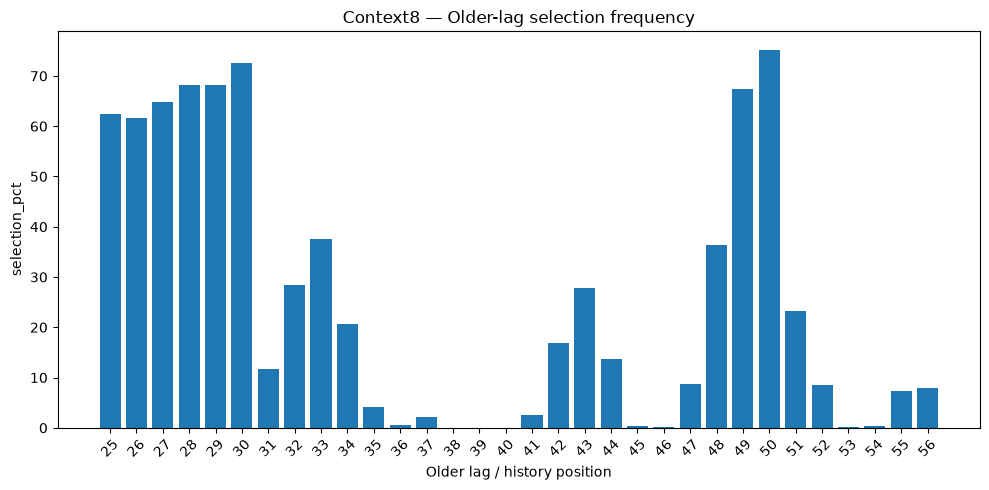

Saved: ..\phase2_preprocessing_outputs\step61_explainability_outputs\step61_context8_old_lag_frequency.png


In [4]:
if LAG_FREQ_PATH is not None:
    lag_df = pd.read_csv(LAG_FREQ_PATH)

    print("Columns:", list(lag_df.columns))
    display(lag_df.head(10))

    # Robustly identify lag/frequency columns across notebook versions.
    lag_col = next(
        (c for c in lag_df.columns if "lag" in c.lower() or "position" in c.lower()),
        lag_df.columns[0]
    )
    freq_col = next(
        (c for c in lag_df.columns if "freq" in c.lower() or "pct" in c.lower() or "percent" in c.lower()),
        lag_df.columns[-1]
    )

    plot_df = lag_df[[lag_col, freq_col]].copy()
    plot_df = plot_df.sort_values(freq_col, ascending=False)

    print("\nTop selected older lags:")
    display(plot_df.head(12).round(3))

    plt.figure(figsize=(10, 5))
    ordered = plot_df.sort_values(lag_col)
    plt.bar(ordered[lag_col].astype(str), ordered[freq_col])
    plt.xlabel("Older lag / history position")
    plt.ylabel(freq_col)
    plt.title("Context8 — Older-lag selection frequency")
    plt.xticks(rotation=45)
    plt.tight_layout()

    LAG_PLOT = OUTPUT_DIR / "step61_context8_old_lag_frequency.png"
    plt.savefig(LAG_PLOT, dpi=160, bbox_inches="tight")
    plt.show()

    plot_df.to_csv(OUTPUT_DIR / "step61_context8_old_lag_frequency.csv", index=False)
    print("Saved:", LAG_PLOT)
else:
    print(
        "No saved Stage-59D lag-frequency CSV was found. "
        "The remaining Step 61 analyses will still run from Step 60 predictions."
    )


## 4. Forecast-horizon analysis


,horizon,fixed_rmse,hybrid_rmse,hybrid_gain_rmse,winner
0,1,184.635,179.805,4.830,Recent24 + Context8
1,2,194.687,193.531,1.156,Recent24 + Context8
2,3,228.737,228.000,0.736,Recent24 + Context8
3,4,185.169,181.508,3.661,Recent24 + Context8
4,5,255.922,246.461,9.461,Recent24 + Context8
5,6,194.852,187.170,7.682,Recent24 + Context8
6,7,154.201,154.199,0.002,Recent24 + Context8
7,8,169.573,167.285,2.288,Recent24 + Context8
8,9,258.632,260.335,-1.704,Fixed Recent-32
9,10,312.925,312.090,0.835,Recent24 + Context8


Horizons won by hybrid: 18 / 28


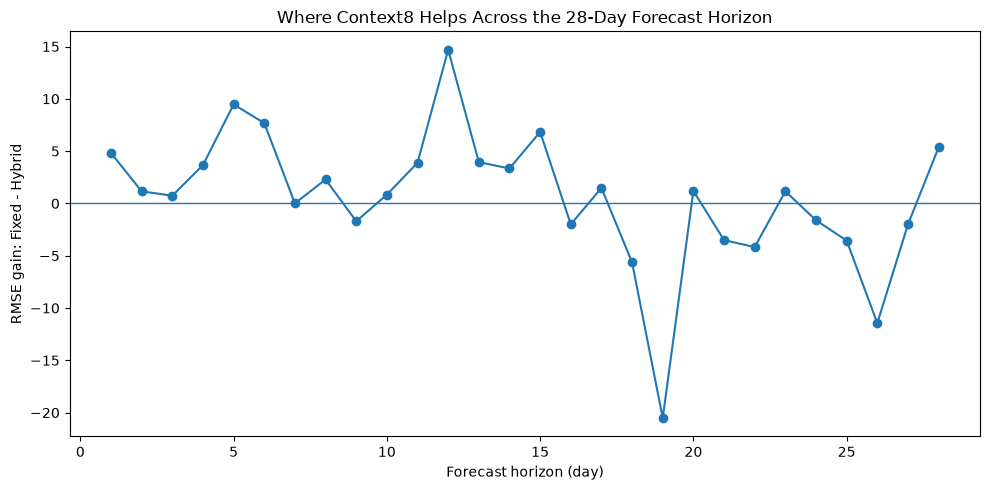

Saved: ..\phase2_preprocessing_outputs\step61_explainability_outputs\step61_horizon_rmse_gain.png


In [5]:
horizon_df = pd.read_csv(HORIZON_CSV)

pivot_rmse = horizon_df.pivot(
    index="horizon",
    columns="Variant",
    values="rmse",
)

assert "Fixed Recent-32" in pivot_rmse.columns
assert "Recent24 + Context8" in pivot_rmse.columns

horizon_compare = pd.DataFrame({
    "horizon": pivot_rmse.index.astype(int),
    "fixed_rmse": pivot_rmse["Fixed Recent-32"].to_numpy(),
    "hybrid_rmse": pivot_rmse["Recent24 + Context8"].to_numpy(),
})

horizon_compare["hybrid_gain_rmse"] = (
    horizon_compare["fixed_rmse"] - horizon_compare["hybrid_rmse"]
)
horizon_compare["winner"] = np.where(
    horizon_compare["hybrid_gain_rmse"] > 0,
    "Recent24 + Context8",
    "Fixed Recent-32",
)

display(horizon_compare.round(3))

print(
    "Horizons won by hybrid:",
    int((horizon_compare["hybrid_gain_rmse"] > 0).sum()),
    "/ 28"
)

plt.figure(figsize=(10, 5))
plt.axhline(0, linewidth=1)
plt.plot(
    horizon_compare["horizon"],
    horizon_compare["hybrid_gain_rmse"],
    marker="o",
)
plt.xlabel("Forecast horizon (day)")
plt.ylabel("RMSE gain: Fixed - Hybrid")
plt.title("Where Context8 Helps Across the 28-Day Forecast Horizon")
plt.tight_layout()

HGAIN_PLOT = OUTPUT_DIR / "step61_horizon_rmse_gain.png"
plt.savefig(HGAIN_PLOT, dpi=160, bbox_inches="tight")
plt.show()

horizon_compare.to_csv(
    OUTPUT_DIR / "step61_horizon_comparison.csv",
    index=False,
)
print("Saved:", HGAIN_PLOT)


## 5. Demand-level context analysis


,demand_group,windows,mean_actual,fixed_rmse,hybrid_rmse,mean_rmse_gain,hybrid_win_rate,hybrid_rmse_gain_pct
0,Low,432,1.723000,1.570000,1.564000,0.005,46.991001,0.331
1,Medium-Low,432,15.936000,8.031000,8.037000,-0.006,50.000000,-0.078
2,Medium-High,432,138.591995,39.205002,39.429001,-0.224,39.583000,-0.572
3,High,432,1781.321045,325.608002,325.239990,0.368,44.907001,0.113


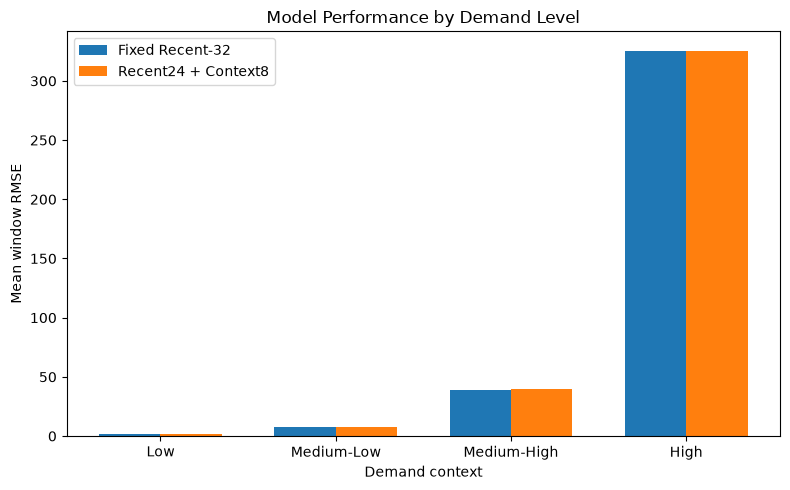

In [6]:
# Demand groups are defined from actual mean sales on the untouched test windows.
# qcut duplicates='drop' protects against repeated zero/low demand values.
window_df["demand_group"] = pd.qcut(
    window_df["actual_mean"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"],
    duplicates="drop",
)

demand_summary = (
    window_df
    .groupby("demand_group", observed=True)
    .agg(
        windows=("actual_mean", "size"),
        mean_actual=("actual_mean", "mean"),
        fixed_rmse=("fixed_rmse", "mean"),
        hybrid_rmse=("hybrid_rmse", "mean"),
        mean_rmse_gain=("rmse_gain_hybrid", "mean"),
        hybrid_win_rate=("rmse_gain_hybrid", lambda x: float((x > 0).mean() * 100)),
    )
    .reset_index()
)

demand_summary["hybrid_rmse_gain_pct"] = (
    (demand_summary["fixed_rmse"] - demand_summary["hybrid_rmse"])
    / demand_summary["fixed_rmse"] * 100.0
)

display(demand_summary.round(3))

plt.figure(figsize=(8, 5))
x = np.arange(len(demand_summary))
w = 0.35
plt.bar(x - w/2, demand_summary["fixed_rmse"], width=w, label="Fixed Recent-32")
plt.bar(x + w/2, demand_summary["hybrid_rmse"], width=w, label="Recent24 + Context8")
plt.xticks(x, demand_summary["demand_group"].astype(str))
plt.ylabel("Mean window RMSE")
plt.xlabel("Demand context")
plt.title("Model Performance by Demand Level")
plt.legend()
plt.tight_layout()

DEMAND_PLOT = OUTPUT_DIR / "step61_demand_group_rmse.png"
plt.savefig(DEMAND_PLOT, dpi=160, bbox_inches="tight")
plt.show()

demand_summary.to_csv(
    OUTPUT_DIR / "step61_demand_group_summary.csv",
    index=False,
)


## 6. Product-family analysis


Families where context-aware hybrid helps most:


,family,windows,mean_actual,fixed_rmse,hybrid_rmse,mean_rmse_gain,hybrid_win_rate,hybrid_gain_pct
4,BOOKS,26,0.030000,0.238000,0.190000,0.049,80.768997,20.361
15,HOME AND KITCHEN I,54,30.858000,14.356000,14.239000,0.117,64.815002,0.817
3,BEVERAGES,54,3539.587891,742.091003,736.578003,5.513,64.815002,0.743
27,PLAYERS AND ELECTRONICS,54,11.572000,4.541000,4.509000,0.033,61.111000,0.721
30,PRODUCE,54,2296.604004,318.123993,315.923004,2.201,50.000000,0.692
28,POULTRY,54,381.343994,67.757004,67.540001,0.217,44.444000,0.320
19,LADIESWEAR,44,13.289000,6.281000,6.269000,0.012,47.727001,0.191
23,MAGAZINES,54,6.909000,3.851000,3.844000,0.007,61.111000,0.182
32,SEAFOOD,54,19.940001,5.771000,5.764000,0.008,61.111000,0.134
17,HOME APPLIANCES,54,0.227000,0.516000,0.516000,0.000,46.296001,0.093


Families where Fixed Recent-32 is stronger:


,family,windows,mean_actual,fixed_rmse,hybrid_rmse,mean_rmse_gain,hybrid_win_rate,hybrid_gain_pct
10,EGGS,54,196.641998,48.646000,50.188000,-1.542,46.296001,-3.170
20,LAWN AND GARDEN,51,16.572001,7.345000,7.508000,-0.163,13.725000,-2.225
25,PERSONAL CARE,54,316.404999,71.646004,72.500000,-0.854,25.926001,-1.191
29,PREPARED FOODS,54,88.122002,20.812000,21.011000,-0.198,33.333000,-0.953
22,"LIQUOR,WINE,BEER",54,100.260002,42.791000,43.174999,-0.384,27.778000,-0.898
9,DELI,54,303.640015,53.488998,53.925999,-0.437,48.147999,-0.816
2,BEAUTY,54,6.112000,3.151000,3.176000,-0.025,31.481001,-0.783
13,GROCERY II,54,32.992001,16.490999,16.599001,-0.108,37.036999,-0.657
11,FROZEN FOODS,54,129.695007,32.590000,32.792000,-0.202,38.889000,-0.620
8,DAIRY,54,840.981995,120.514000,121.157997,-0.644,40.741001,-0.534


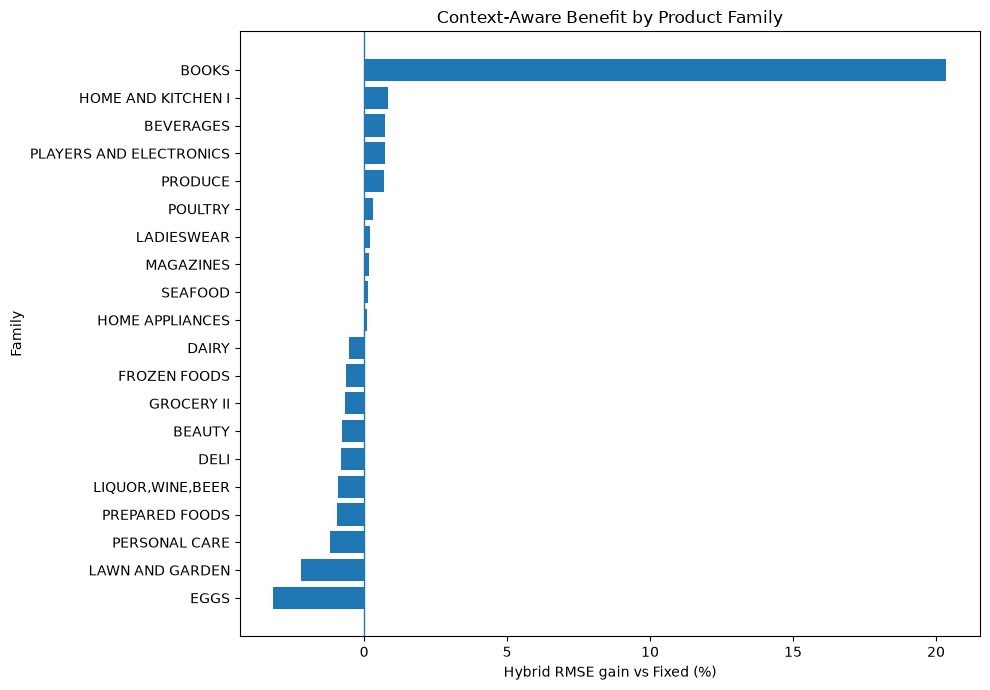

In [7]:
family_summary = (
    window_df
    .groupby("family")
    .agg(
        windows=("family", "size"),
        mean_actual=("actual_mean", "mean"),
        fixed_rmse=("fixed_rmse", "mean"),
        hybrid_rmse=("hybrid_rmse", "mean"),
        mean_rmse_gain=("rmse_gain_hybrid", "mean"),
        hybrid_win_rate=("rmse_gain_hybrid", lambda x: float((x > 0).mean() * 100)),
    )
    .reset_index()
)

family_summary["hybrid_gain_pct"] = (
    (family_summary["fixed_rmse"] - family_summary["hybrid_rmse"])
    / family_summary["fixed_rmse"] * 100.0
)

eligible_family = family_summary[family_summary["windows"] >= 3].copy()

best_families = eligible_family.sort_values(
    "hybrid_gain_pct", ascending=False
).head(10)

worst_families = eligible_family.sort_values(
    "hybrid_gain_pct", ascending=True
).head(10)

print("Families where context-aware hybrid helps most:")
display(best_families.round(3))

print("Families where Fixed Recent-32 is stronger:")
display(worst_families.round(3))

family_summary.to_csv(
    OUTPUT_DIR / "step61_family_summary.csv",
    index=False,
)

plot_family = pd.concat([
    best_families.assign(group="Hybrid helps"),
    worst_families.assign(group="Fixed helps"),
]).drop_duplicates("family")

plot_family = plot_family.sort_values("hybrid_gain_pct")

plt.figure(figsize=(10, 7))
plt.barh(plot_family["family"].astype(str), plot_family["hybrid_gain_pct"])
plt.axvline(0, linewidth=1)
plt.xlabel("Hybrid RMSE gain vs Fixed (%)")
plt.ylabel("Family")
plt.title("Context-Aware Benefit by Product Family")
plt.tight_layout()

FAMILY_PLOT = OUTPUT_DIR / "step61_family_context_gain.png"
plt.savefig(FAMILY_PLOT, dpi=160, bbox_inches="tight")
plt.show()


## 7. Store-level analysis


In [8]:
store_summary = (
    window_df
    .groupby("store_nbr")
    .agg(
        windows=("store_nbr", "size"),
        mean_actual=("actual_mean", "mean"),
        fixed_rmse=("fixed_rmse", "mean"),
        hybrid_rmse=("hybrid_rmse", "mean"),
        mean_rmse_gain=("rmse_gain_hybrid", "mean"),
        hybrid_win_rate=("rmse_gain_hybrid", lambda x: float((x > 0).mean() * 100)),
    )
    .reset_index()
)

store_summary["hybrid_gain_pct"] = (
    (store_summary["fixed_rmse"] - store_summary["hybrid_rmse"])
    / store_summary["fixed_rmse"] * 100.0
)

eligible_store = store_summary[store_summary["windows"] >= 3].copy()

print("Stores where hybrid helps most:")
display(
    eligible_store.sort_values("hybrid_gain_pct", ascending=False)
    .head(10).round(3)
)

print("Stores where Fixed Recent-32 is stronger:")
display(
    eligible_store.sort_values("hybrid_gain_pct", ascending=True)
    .head(10).round(3)
)

store_summary.to_csv(
    OUTPUT_DIR / "step61_store_summary.csv",
    index=False,
)


Stores where hybrid helps most:


,store_nbr,windows,mean_actual,fixed_rmse,hybrid_rmse,mean_rmse_gain,hybrid_win_rate,hybrid_gain_pct
42,43,31,516.208984,109.453003,106.247002,3.206,58.064999,2.929
26,27,33,456.506012,76.504997,74.863998,1.641,51.514999,2.145
20,21,32,444.720001,105.600998,103.421997,2.180,31.250000,2.064
46,47,32,1163.901001,182.266006,179.188004,3.077,37.500000,1.688
27,28,31,491.244995,119.306000,117.348000,1.958,45.160999,1.641
49,50,32,662.078003,109.394997,107.712997,1.681,53.125000,1.537
47,48,32,799.155029,150.865005,149.009003,1.856,53.125000,1.230
35,36,32,389.311005,99.102997,97.921997,1.181,56.250000,1.192
37,38,33,395.438995,118.870003,117.617996,1.252,54.544998,1.054
4,5,33,304.645996,46.097000,45.622002,0.476,48.485001,1.032


Stores where Fixed Recent-32 is stronger:


,store_nbr,windows,mean_actual,fixed_rmse,hybrid_rmse,mean_rmse_gain,hybrid_win_rate,hybrid_gain_pct
6,7,33,550.385986,76.625999,78.195999,-1.570,45.455002,-2.049
48,49,32,1016.377991,122.165001,124.558998,-2.395,46.875000,-1.960
17,18,32,310.502014,52.632000,53.585999,-0.953,53.125000,-1.811
7,8,33,634.331970,75.799004,77.123001,-1.324,39.394001,-1.746
18,19,32,293.319000,56.356998,57.311001,-0.953,46.875000,-1.692
23,24,33,521.169983,67.713997,68.823997,-1.110,36.363998,-1.639
53,54,30,353.769989,121.357002,123.216003,-1.859,60.000000,-1.532
28,29,31,409.194000,84.758003,86.014000,-1.257,41.935001,-1.483
50,51,32,731.918030,106.324997,107.853996,-1.529,50.000000,-1.438
38,39,32,517.083008,151.656998,153.781006,-2.124,40.625000,-1.400


## 8. Representative examples


,case,index,store_nbr,family,actual_mean,fixed_rmse,hybrid_rmse,rmse_gain_hybrid
0,Best hybrid gain,1476,47,BEVERAGES,9088.821289,1656.581055,1525.171021,131.410004
1,Worst hybrid gain,1701,54,BEVERAGES,3717.677979,2095.049072,2190.345947,-95.296997
2,Near-tie case,1669,53,BOOKS,0.000000,0.000000,0.000000,0.000000


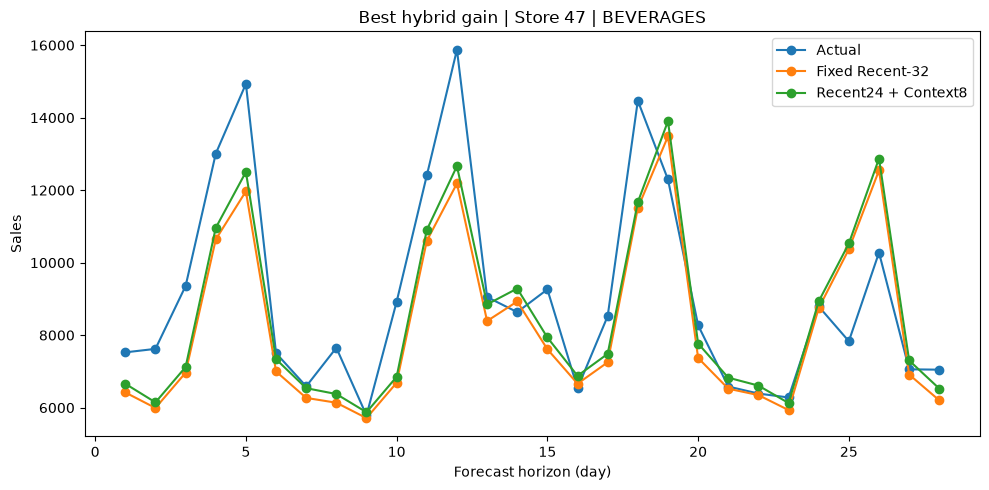

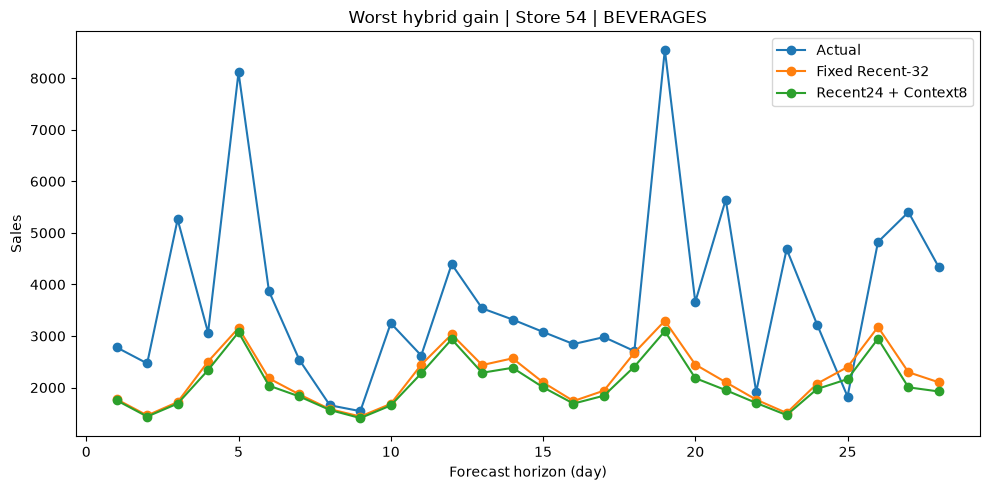

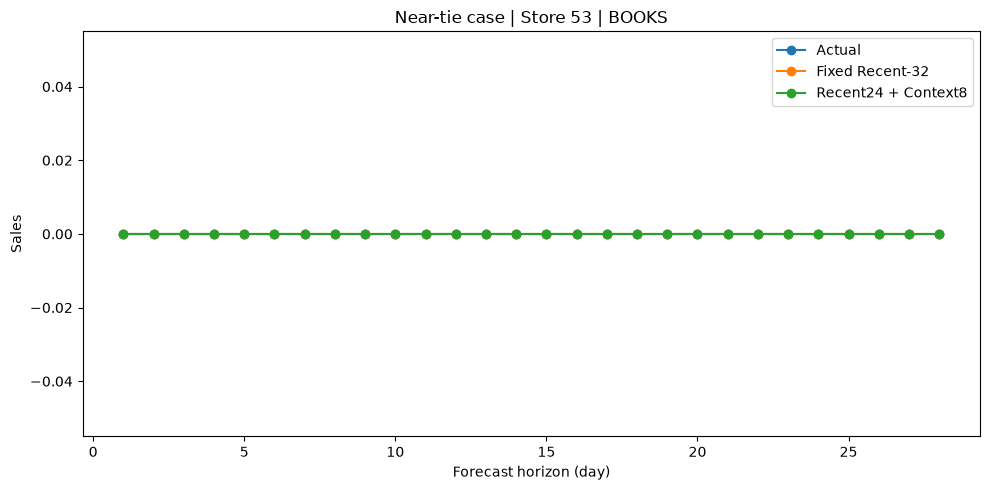

In [9]:
best_idx = int(window_df["rmse_gain_hybrid"].idxmax())
worst_idx = int(window_df["rmse_gain_hybrid"].idxmin())
typical_idx = int(window_df["rmse_gain_hybrid"].abs().idxmin())

example_indices = {
    "Best hybrid gain": best_idx,
    "Worst hybrid gain": worst_idx,
    "Near-tie case": typical_idx,
}

example_rows = []

for label, idx in example_indices.items():
    row = window_df.loc[idx]
    example_rows.append({
        "case": label,
        "index": idx,
        "store_nbr": row["store_nbr"],
        "family": row["family"],
        "actual_mean": row["actual_mean"],
        "fixed_rmse": row["fixed_rmse"],
        "hybrid_rmse": row["hybrid_rmse"],
        "rmse_gain_hybrid": row["rmse_gain_hybrid"],
    })

display(pd.DataFrame(example_rows).round(3))

for label, idx in example_indices.items():
    plt.figure(figsize=(10, 5))
    h = np.arange(1, 29)
    plt.plot(h, y_true[idx], marker="o", label="Actual")
    plt.plot(h, y_fixed[idx], marker="o", label="Fixed Recent-32")
    plt.plot(h, y_hybrid[idx], marker="o", label="Recent24 + Context8")
    plt.xlabel("Forecast horizon (day)")
    plt.ylabel("Sales")
    plt.title(
        f"{label} | Store {window_df.loc[idx, 'store_nbr']} | "
        f"{window_df.loc[idx, 'family']}"
    )
    plt.legend()
    plt.tight_layout()

    safe_label = (
        label.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )
    p = OUTPUT_DIR / f"step61_example_{safe_label}.png"
    plt.savefig(p, dpi=160, bbox_inches="tight")
    plt.show()

pd.DataFrame(example_rows).to_csv(
    OUTPUT_DIR / "step61_representative_examples.csv",
    index=False,
)


## 9. How often does context help?


,Outcome,Percent of test windows
0,Hybrid better,45.37
1,Approximately tied,0.06
2,Fixed better,54.57


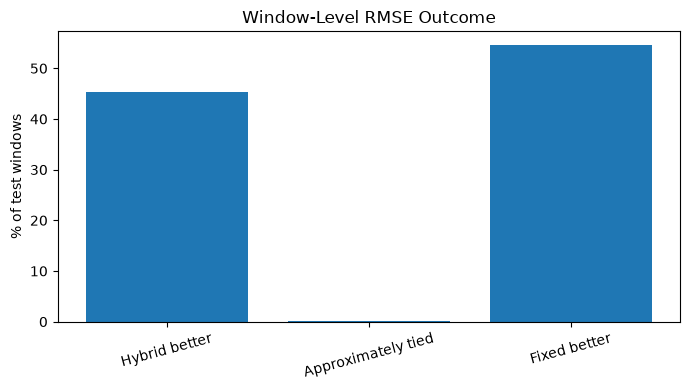

In [10]:
win_rate = float((window_df["rmse_gain_hybrid"] > 0).mean() * 100.0)
tie_rate = float((np.isclose(window_df["rmse_gain_hybrid"], 0, atol=1e-6)).mean() * 100.0)
loss_rate = 100.0 - win_rate - tie_rate

summary_win = pd.DataFrame({
    "Outcome": ["Hybrid better", "Approximately tied", "Fixed better"],
    "Percent of test windows": [win_rate, tie_rate, loss_rate],
})

display(summary_win.round(2))

plt.figure(figsize=(7, 4))
plt.bar(summary_win["Outcome"], summary_win["Percent of test windows"])
plt.ylabel("% of test windows")
plt.title("Window-Level RMSE Outcome")
plt.xticks(rotation=15)
plt.tight_layout()

WIN_PLOT = OUTPUT_DIR / "step61_window_win_rate.png"
plt.savefig(WIN_PLOT, dpi=160, bbox_inches="tight")
plt.show()


## 10. Thesis-ready explainability summary


In [11]:
overall_df = pd.read_csv(OVERALL_CSV)

fixed_test = overall_df.loc[
    overall_df["Variant"] == "Fixed Recent-32"
].iloc[0]

hybrid_test = overall_df.loc[
    overall_df["Variant"] == "Recent24 + Context8"
].iloc[0]

test_gap_pct = (
    float(hybrid_test["rmse"]) / float(fixed_test["rmse"]) - 1.0
) * 100.0

best_demand = (
    demand_summary
    .sort_values("hybrid_rmse_gain_pct", ascending=False)
    .iloc[0]
)

best_family = (
    eligible_family
    .sort_values("hybrid_gain_pct", ascending=False)
    .iloc[0]
    if len(eligible_family)
    else None
)

print("=== STEP 61 EXPLAINABILITY FINDINGS ===")
print()
print(
    "1. Final test RMSE: Recent24 + Context8 =",
    round(float(hybrid_test["rmse"]), 4),
    "| Fixed Recent-32 =",
    round(float(fixed_test["rmse"]), 4),
)
print(
    "   Hybrid RMSE change vs Fixed =",
    round(test_gap_pct, 3),
    "%"
)
print()
print(
    "2. The architecture preserves the latest 24 observations and uses the selector",
    "only for 8 older historical positions."
)
print()
print(
    "3. Hybrid wins at",
    int((horizon_compare["hybrid_gain_rmse"] > 0).sum()),
    "of 28 forecast horizons."
)
print()
print(
    "4. Hybrid has lower window-level RMSE in",
    round(win_rate, 2),
    "% of untouched test windows."
)
print()
print(
    "5. Demand context with strongest average hybrid gain:",
    str(best_demand["demand_group"]),
    "| gain =",
    round(float(best_demand["hybrid_rmse_gain_pct"]), 3),
    "%"
)

if best_family is not None:
    print(
        "6. Example family with strongest hybrid gain (>=3 windows):",
        str(best_family["family"]),
        "| gain =",
        round(float(best_family["hybrid_gain_pct"]), 3),
        "%"
    )

print()
print(
    "Interpretation: context-aware historical retrieval is selectively useful.",
    "Its benefit depends on the forecasting context rather than improving every",
    "store, family, demand level, and horizon uniformly."
)

THESIS_SUMMARY = OUTPUT_DIR / "step61_thesis_ready_findings.txt"

with open(THESIS_SUMMARY, "w", encoding="utf-8") as f:
    f.write("STEP 61 EXPLAINABILITY FINDINGS\n\n")
    f.write(
        f"Recent24 + Context8 test RMSE: {float(hybrid_test['rmse']):.6f}\n"
    )
    f.write(
        f"Fixed Recent-32 test RMSE: {float(fixed_test['rmse']):.6f}\n"
    )
    f.write(
        f"Hybrid RMSE change vs Fixed: {test_gap_pct:.6f}%\n"
    )
    f.write(
        f"Hybrid-winning forecast horizons: "
        f"{int((horizon_compare['hybrid_gain_rmse'] > 0).sum())}/28\n"
    )
    f.write(
        f"Hybrid-winning test windows: {win_rate:.6f}%\n"
    )
    f.write(
        f"Strongest demand context: {best_demand['demand_group']} "
        f"({float(best_demand['hybrid_rmse_gain_pct']):.6f}% gain)\n"
    )
    if best_family is not None:
        f.write(
            f"Example strongest family: {best_family['family']} "
            f"({float(best_family['hybrid_gain_pct']):.6f}% gain)\n"
        )
    f.write(
        "\nInterpretation: preserving recent history provides stability, "
        "while adaptive retrieval of older context contributes selectively "
        "depending on forecast horizon and retail context.\n"
    )

print("\nSaved:", THESIS_SUMMARY)
print("All Step 61 outputs:", OUTPUT_DIR)


=== STEP 61 EXPLAINABILITY FINDINGS ===

1. Final test RMSE: Recent24 + Context8 = 242.1152 | Fixed Recent-32 = 242.6735
   Hybrid RMSE change vs Fixed = -0.23 %

2. The architecture preserves the latest 24 observations and uses the selector only for 8 older historical positions.

3. Hybrid wins at 18 of 28 forecast horizons.

4. Hybrid has lower window-level RMSE in 45.37 % of untouched test windows.

5. Demand context with strongest average hybrid gain: Low | gain = 0.331 %
6. Example family with strongest hybrid gain (>=3 windows): BOOKS | gain = 20.361 %

Interpretation: context-aware historical retrieval is selectively useful. Its benefit depends on the forecasting context rather than improving every store, family, demand level, and horizon uniformly.

Saved: ..\phase2_preprocessing_outputs\step61_explainability_outputs\step61_thesis_ready_findings.txt
All Step 61 outputs: ..\phase2_preprocessing_outputs\step61_explainability_outputs


## Key findings

- Hybrid RMSE is lower in **18 of 28 forecast horizons**.
- Hybrid RMSE is lower in **784 of 1,728 test windows (45.37%)**.
- Older-history retrieval is strongly non-uniform.
- Frequently retrieved older positions include **lag 50, lag 30, lag 28, lag 29 and lag 49**.
- Benefits vary across stores, families and demand levels.

### Interpretation caution
A frequently selected lag means that the trained selector considered that historical position useful for prediction. It does **not** establish causal importance or prove weekly/monthly seasonality.
